# DFA and Factor Investing

## HBS Case
### *Dimensional Fund Advisors, 2002* [HBS 9-203-026]

Pages 1-5 of the case are required. Pages 6-11 discuss trading (especially adverse selection) and taxes. These sections are useful for market background, but are optional.

# 1. READING - DFA's Strategy

#### 1. Investment philosophy.

* In 100 words or less, describe DFA's belief about how to find premium in the market.

    > DFA believes that investment premiums can be captured through systematic exposure to risk factors rather than individual stock selection. 
    > 
    > Based on the "efficient markets" theory, DFA argues that consistently higher expected returns reflect compensation for bearing additional risk, not exploitable mispricing. Academic research identified two important sources of premiums: the size premium, associated with small-cap stocks, and the value premium, associated with stocks with high book-to-market ratios.  DFA seeks to capture these premiums through broadly diversified, low-cost portfolios while using efficient trading strategies to enhance returns.

* To what degree does their strategy rely on individual equity analysis? Macroeconomic fundamentals? Efficient markets?

    > DFA's strategy relies minimally on individual equity analysis or macroeconomic forecasting and heavily on the efficient markets hypothesis. 
    > 
    > Instead of identifying mispriced securities through fundamental analysis or attempting to time economic cycles, DFA constructs diversified portfolios based on academically documented risk factors, particularly size and value. Its belief in market efficiency implies that publicly available information is already reflected in stock prices, making consistent stock-picking outperformance unlikely. However, DFA still uses research and trading expertise to implement its strategies efficiently, minimize transaction costs, and capture systematic return premiums.

* Are DFA's funds active or passive?

    > Passive. Unlike traditional active managers, DFA does not attempt to outperform through individual stock selection or market timing. However, its funds are not pure index funds because they deliberately emphasize stocks with characteristics associated with higher expected returns, particularly small capitalization and high book-to-market ratios. DFA also employs active trading strategies to reduce transaction costs and obtain favorable execution prices. Thus, its investment philosophy is largely passive, while its portfolio construction and trading incorporate active decisions.

* What do DFA and others mean by a "value" stock? And a "growth" stock?

    > Value stocks are stocks with high book-to-market ratios which mean that their market valuations are relatively low compared with the accounting value of their equity. These companies often have weaker recent performance or face financial distress which potentially explain thei rhigher expected returns as compensation for risk. 
    > 
    > On the other hand, growth stocks are stocks with low book-to-market ratios, reflecting relatively high market valuations compared with book equity (often because investors anticipate strong future growth). DFA favors value stocks because academic research documents a historical value premium, which DFA interprets primarily as compensation for bearing additional systematic risk rather than evidence of market mispricing.

#### 2. Challenges for DFA's view.

* What challenge did DFA's model see in the 1980's?

    > During the 1980s, DFA faced prolonged underperformance of small-cap stocks relative to large-cap stocks, particularly the S&P 500. Although its small-cap funds generally performed well relative to comparable small-cap benchmarks, the broader size premium failed to materialize consistently. 
    > 
    > This challenged DFA's investment philosophy because its original strategy was built on academic evidence that small stocks historically earned higher average returns. Critics questioned whether the size premium had disappeared after becoming widely known or whether its historical performance had been anomalous. DFA maintained that systematic risk premiums could experience extended periods of underperformance without necessarily disappearing.

* And in the 1990's?

    > During the 1990s, particularly the late-1990s technology boom, DFA faced substantial underperformance of value stocks relative to growth stocks. High-valuation technology companies generated exceptional returns, while DFA's value-oriented portfolios largely avoided these stocks because of their low book-to-market ratios. 
    > 
    > This challenged DFA's belief in a persistent value premium and tested investors' willingness to maintain long-term factor exposures through extended periods of relative underperformance. However, the collapse of technology and growth stocks in 2000–2001 led to substantial value outperformance, reinforcing DFA's argument that temporary underperformance does not necessarily invalidate a systematic return premium.

#### 3. The market.

* Exhibit 3 has data regarding a universe of 5,020 firms. How many are considered "large cap"? What percent of the market value do they account for?

    > According to Exhibit 3, 207 of the 5,020 firms are classified as large cap, representing approximately 4.12% of all firms. Despite their small share of the total number of companies, these large-cap firms account for 70% of total market capitalization. 
    > 
    > This illustrates the substantial concentration of market value among the largest companies and helps explain why capitalization-weighted market indexes are dominated by large-cap stocks.

* Exhibit 6 shows that the U.S. value factor (HML) has underperformed the broader U.S. equity market in 1926-2001, including every subsample except 1963-1981. So why should an investor be interested in this value factor?**

    > Although the US value factor (HML) earned a lower average return than the broader equity market over 1926–2001, it may still be attractive because of its diversification benefits and distinct source of expected returns. 
    > 
    > HML captures the return premium associated with high book-to-market stocks relative to low book-to-market stocks, rather than simply providing additional market exposure. If HML is imperfectly correlated with the market, incorporating it into a portfolio can potentially improve risk-adjusted performance by reducing overall portfolio volatility. Therefore, investors should evaluate HML based on its marginal contribution to portfolio risk and return, rather than its standalone average return. Its positive historical premium also suggests that value exposure may provide compensation for risks not fully captured by the market factor.

# 2. The Factors

DFA believes certain stocks have higher expected excess returns. In addition to the overall market equity premium, DFA believes that there is a premium attached to a **size** and **value** factor.

### Data

Use `data/dfa_analysis_data.xlsx` from the [course Box folder](https://uchicago.app.box.com/s/w3oqz9iy0kav3n3l4pa04p6etndo2ez2). Monthly data covers July 1926 through August 2026. Returns are stored as decimals.

- **Factors:** Use all three columns, `Mkt-RF`, `SMB`, and `HML`, in the `factors` sheet for Section 2. They are already excess returns; do not subtract `RF` from them.
- **Risk-free return:** `RF` is the monthly risk-free return. Use it to convert the portfolios' total returns to excess returns in Section 3.
- **Portfolios:** The `portfolios (total returns)` sheet contains 25 value-weighted portfolios sorted by size and book-to-market.

Source: [Ken French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html).

In [57]:
import pandas as pd
import numpy as np

returns = pd.read_excel("dfa_analysis_data.xlsx", sheet_name = "portfolios (total returns)")
returns = returns.set_index("Date")
factors = pd.read_excel("dfa_analysis_data.xlsx", sheet_name = "factors")
factors = factors.set_index("Date")

### 1. The Factors

Calculate the univariate performance statistics for each of the three factors: 

* annualized mean
* annualized volatility
* annualized Sharpe ratio
* monthly VaR(.05), reported as the fifth percentile of returns

Report these for the following three subsamples:

* July 1926 - December 1980
* January 1981 - December 2001
* January 2002 - August 2026

In [76]:
factor_cols = ["Mkt-RF", "SMB", "HML"]

subsamples = {"Jul 1926 – Dec 1980": factors.loc["1926-07":"1980-12"],
              "Jan 1981 – Dec 2001": factors.loc["1981-01":"2001-12"],
              "Jan 2002 - Aug 2026": factors.loc["2002-01":"2026-08"]}

def summary_stats(df):
    stats = pd.DataFrame({"Annualized Mean": df.mean() * 12,
                          "Annualized Volatility": df.std() * np.sqrt(12),
                          "Annualized Sharpe": df.mean() / df.std() * np.sqrt(12),
                          "Monthly VaR (0.05)": df.quantile(0.05)})
    return stats

factor_stats = pd.concat({period: summary_stats(df) for period, df in subsamples.items()}, names = ["Period", "Factor"])

factor_stats = factor_stats.loc[(slice(None), factor_cols), :]

display(factor_stats.style.format({"Annualized Mean": "{:.2%}",
                                   "Annualized Volatility": "{:.2%}",
                                   "Annualized Sharpe": "{:.2f}",
                                   "Monthly VaR (0.05)": "{:.2%}"}))

### 2. 

Based on the factor statistics above, answer the following.

- Does each factor have a premium (positive expected excess return) in each subsample?

    > No. The SMB factor earns a slightly negative premium of -0.20% in 1981-2001. 

- Does the premium to the size factor get smaller after 1980?

    > Yes, the size premium weakens substantially after 1980. SMB's annualized mean return declines from 3.39% in 1926–1980 to −0.20% in 1981–2001, before recovering slightly to 0.75% in 2002–2026. Its Sharpe ratio similarly declines from 0.2969 to −0.0172 and then 0.0860. This is consistent with the DFA case, which describes how small-cap stocks underperformed large-cap stocks during the 1980s and 1990s, despite their historically strong performance. The results suggest that the size premium became considerably weaker after DFA began implementing its small-cap investment strategy.

- Does the premium to the value factor get smaller during the 1990's?

    > Yes, the value premium weakened substantially during the 1990s. HML earned an annualized mean return of only 0.05% during 1990–1999 (see below), indicating that value stocks barely outperformed growth stocks on average over the decade. This is consistent with the DFA case, which describes the strong performance of growth stocks, particularly technology companies, during the late 1990s. Although the broader 1981–2001 subsample exhibits a substantially higher HML premium of 6.44%, this average includes the 1980s and the strong value rebound in 2000s. Therefore, the decade-specific result provides clearer evidence of the weak realized value premium during the 1990s, although the shorter sample makes the estimate less precise.

In [73]:
hml_1990s_comparison = pd.DataFrame({"Annualized HML Mean": {"1980s": factors.loc["1981":"1989", "HML"].mean() * 12,
                                                             "1990s": factors.loc["1990":"1999", "HML"].mean() * 12,
                                                             "2000s": factors.loc["2000":"2010", "HML"].mean() * 12}})

display(hml_1990s_comparison.style.format("{:.2%}"))

,Annualized HML Mean
1980s,8.73%
1990s,0.05%
2000s,6.90%


- How have the factors performed since the time of the case, (January 2002 - August 2026)?

    > Since 2001, the market factor has performed strongly, earning an annualized mean return of 9.38% and a Sharpe ratio of 0.6151. In contrast, the size and value factors have delivered substantially weaker performance. SMB earns an annualized premium of only 0.75%, with a Sharpe ratio of 0.0860, while HML earns just 0.55%, with a Sharpe ratio of 0.0521. Although both factors maintain slightly positive realized premiums, their low Sharpe ratios indicate limited standalone risk-adjusted performance. 
    > 
    > Overall, the post-2001 evidence suggests that the market premium has remained robust, while the historical size and value premiums have become considerably less pronounced.

### 3.

The factors are constructed in such a way as to reduce correlation between them.

* Report the correlation matrix across the three factors. 

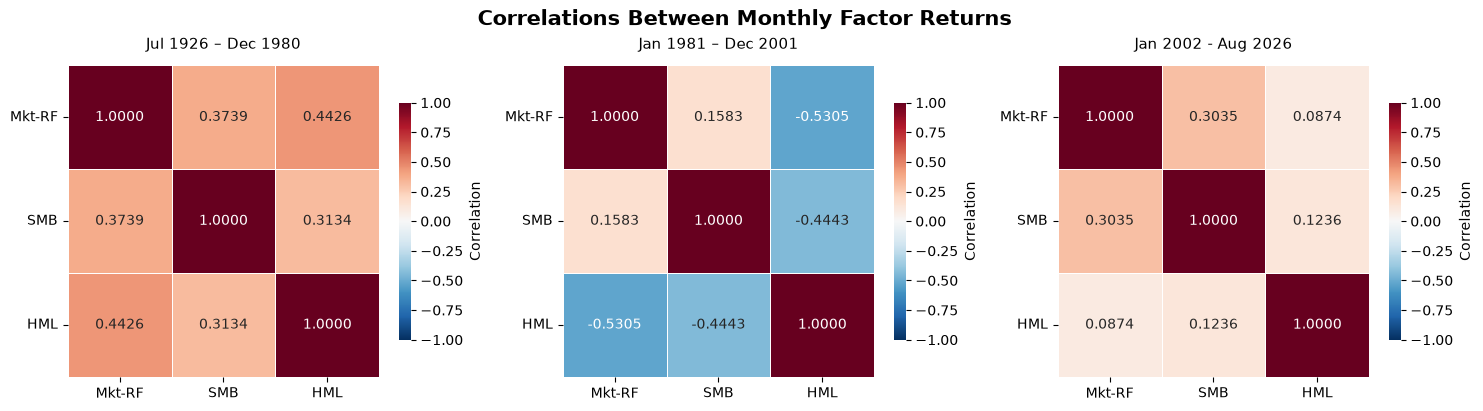

In [86]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize = (15, 4))

for ax, (period, df) in zip(axes.flat, subsamples.items()):
    sns.heatmap(df[factor_cols].corr(), annot = True, fmt = ".4f", cmap = "RdBu_r", vmin = -1, vmax = 1, center = 0, square = True, linewidths = 0.5, 
                cbar_kws = {"label": "Correlation", "shrink": 0.75}, ax = ax)

    ax.set_title(period, fontsize = 11, pad = 12)
    ax.tick_params(axis = "both", labelrotation = 0)

fig.suptitle("Correlations Between Monthly Factor Returns", fontsize = 15, fontweight = "bold", y = 0.98)

plt.tight_layout()
plt.show()

* Does the construction method succeed in keeping correlations small? 
    > The Fama-French factor construction generally succeeds in keeping correlations relatively small by controlling for overlapping size and value exposures. 
    > 
    > The factors are designed to capture distinct sources of systematic returns, with SMB isolating the size premium and HML isolating the value premium. Although correlations are not necessarily zero, their generally low-to-moderate magnitudes suggest that the factors provide meaningful diversification potential rather than simply replicating the same underlying risk exposure.

* Does it achieve this in each subsample?
    > The construction method is not equally effective across all subsamples. During 1926–1980, correlations are moderately positive, with SMB and HML exhibiting the weakest correlation at 0.3134. During 1981–2001, Mkt-RF and SMB have the smallest absolute correlation at 0.1583, while HML exhibits moderately negative correlations with both factors. In 2002–2026, correlations are generally smaller in magnitude, with Mkt-RF and HML exhibiting the weakest correlation at 0.0874. 
    > 
    > Overall, the results suggest that the factors provide relatively distinct exposures, particularly in the most recent subsample, although correlations vary over time.

### 4. 

* Plot the cumulative returns of the three factors. 

* Create plots for the 1981-2001 subsample as well as the January 2002 - August 2026 subsample.

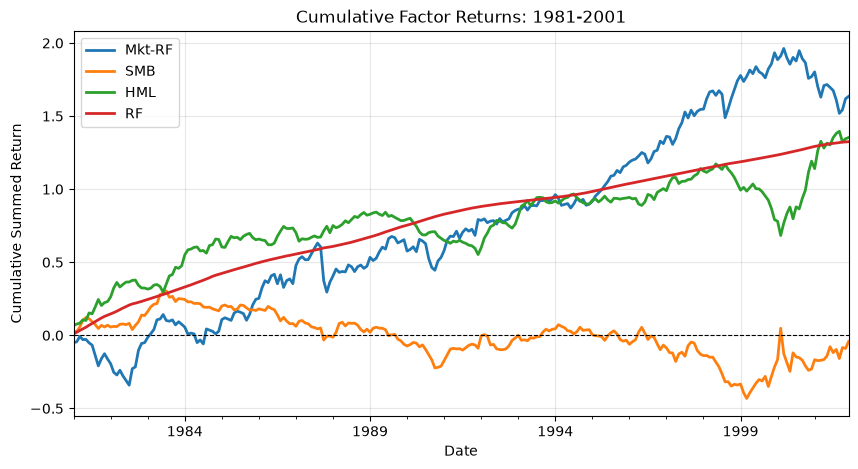

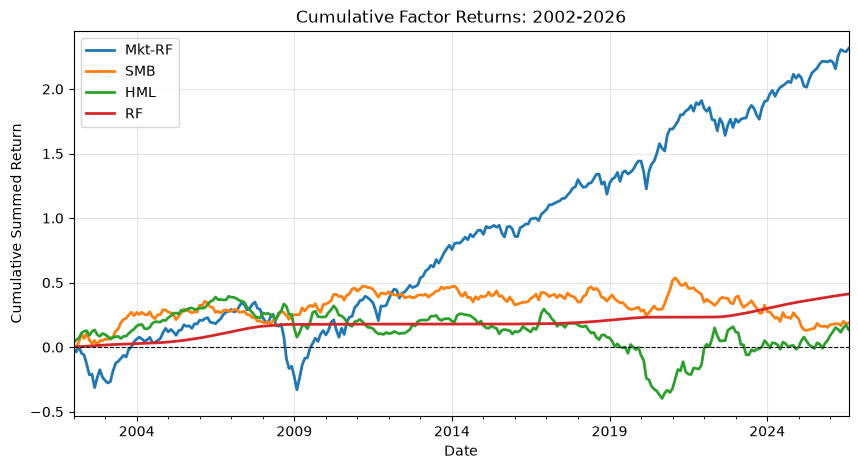

In [ ]:
def plot_cumulative(df, title):
    ax = df.cumsum().plot(figsize = (10, 5), linewidth = 2)
    ax.set(title = title, xlabel = "Date", ylabel = "Cumulative Summed Return")
    ax.axhline(0, color = "black", linestyle = "--", linewidth = 0.8)
    ax.grid(alpha = 0.3)
    plt.show()

for period in ["1981-2001", "2002-2026"]:
    plot_cumulative(subsamples[period], f"Cumulative Factor Returns: {period}")

### 5.

* Does it appear that all three factors were valuable in 1981-2001? 
* And post-2001? 

Would you advise DFA to continue emphasizing all three factors?

> During 1981–2001, Mkt-RF and HML delivered strong performance, with annualized mean returns of 7.78% and 6.44% and Sharpe ratios of 0.50 and 0.59, respectively. 
> 
> In contrast, SMB underperformed, earning a slightly negative annualized return of −0.20% and a Sharpe ratio of −0.02. After 2001, Mkt-RF remained strong, with an annualized return of 9.38% and a Sharpe ratio of 0.62, while SMB and HML weakened considerably, earning only 0.75% and 0.55%, respectively, with Sharpe ratios below 0.10. 
>
> Overall, the market factor has consistently delivered attractive risk-adjusted returns, while the size and value factors have exhibited less persistent premiums. 
> 
> Nevertheless, DFA should continue emphasizing systematic factor investing, as prolonged underperformance does not necessarily invalidate the existence of long-term risk premiums. However, the weak post-2001 performance of SMB and HML suggests that DFA should remain cautious about assuming historical premiums will persist, and should evaluate these factors based on their expected returns, diversification benefits, and implementation costs rather than historical performance alone.

# 3. CAPM

DFA believes that premia in stocks and stock portfolios are related to the three factors. 

Let's test `25` equity portfolios that span a wide range of size and value measures.

#### Footnote
For more on the portfolio construction, see the description at Ken French's data library. 
https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/tw_5_ports.html

#### Portfolios
Monthly **total** return data on `25` equity portfolios sorted by their size-value characteristics. Denote these as $\vec{r}^{i}$, for $n=1, \ldots, 25$.
- Note that while the factors were given as excess returns, the portfolios are total returns.
- For this entire problem, focus on the January 1981 - August 2026 subsample.

### 1. Summary Statistics. 

For each portfolio, 
- Use the `RF` column in the `factors` sheet to convert these total returns to excess returns.
- Calculate the (annualized) univariate statistics from `2.1`; keep VaR at the monthly frequency.

In [87]:
excess_returns = returns.loc["1981-01":"2026-08"].sub(factors["RF"], axis = 0)

portfolio_stats = summary_stats(excess_returns)

display(portfolio_stats.style.format({"Annualized Mean": "{:.2%}",
                                      "Annualized Volatility": "{:.2%}",
                                      "Annualized Sharpe": "{:.2f}",
                                      "Monthly VaR (0.05)": "{:.2%}"}))

,Annualized Mean,Annualized Volatility,Annualized Sharpe,Monthly VaR (0.05)
SMALL LoBM,1.63%,27.11%,0.06,-12.26%
ME1 BM2,9.28%,23.43%,0.40,-9.57%
ME1 BM3,9.62%,20.03%,0.48,-8.44%
ME1 BM4,11.68%,19.26%,0.61,-7.72%
SMALL HiBM,13.05%,20.67%,0.63,-8.72%
ME2 BM1,6.61%,24.37%,0.27,-10.25%
ME2 BM2,10.51%,20.49%,0.51,-8.35%
ME2 BM3,11.10%,18.64%,0.60,-7.90%
ME2 BM4,10.97%,18.10%,0.61,-7.50%
ME2 BM5,11.61%,21.24%,0.55,-9.24%


> The 25 size- and book-to-market-sorted portfolios exhibit substantial differences in risk and return over January 1981–August 2026. In particular, the results provide evidence of a value premium, especially among small-cap stocks. The SMALL HiBM portfolio earns an annualized mean excess return of 13.05% and a Sharpe ratio of 0.63, compared with only 1.63% and 0.06 for SMALL LoBM. This represents an annualized return difference of 11.42 percentage points.
>
> The size premium is less consistent across book-to-market categories. Among growth stocks, BIG LoBM outperforms SMALL LoBM (9.52% versus 1.63%), whereas among value stocks, SMALL HiBM slightly outperforms BIG HiBM (13.05% versus 11.77%). This suggests that the relationship between size and returns depends partly on value characteristics.
>
> In terms of risk, SMALL LoBM exhibits the highest annualized volatility (27.11%) and the most negative monthly 5% VaR (−12.26%), alongside the lowest Sharpe ratio (0.06). Overall, the results suggest that value-oriented portfolios, particularly small-value stocks, delivered stronger historical risk-adjusted performance, consistent with DFA's investment philosophy.

### 2. CAPM

The Capital Asset Pricing Model (CAPM) asserts that an asset (or portfolio's) expected excess return is completely a function of its beta to the equity market index (`Mkt-RF` in this workbook). 

Specifically, it asserts that, for any excess return, $\tilde{r}^{i}$, its mean is proportional to the mean excess return of the market, $\tilde{r}^{\text{mkt}}$, where the proportionality is the regression beta of $\tilde{r}^{i}$ on $\tilde{r}^{\text{mkt}}$.

$$
\mathbb{E}\left[\tilde{r}_{t}^{i}\right] = \beta^{i,\text{mkt}}\; \mathbb{E}\left[\tilde{r}_{t}^{\text{mkt}}\right]
$$

Let's examine whether that seems plausible.

For each of the $n=25$ test portfolios, run the CAPM time-series regression:

$$
\tilde{r}_{t}^{i} = \alpha^i + \beta^{i,\text{mkt}}\; \tilde{r}_{t}^{\text{mkt}} + \epsilon_{t}^{i}
$$

So you are running 25 separate regressions, each using the $T$-sized sample of time-series data.

* Report the betas and alphas for each test asset.

* Report the mean-absolute-error of the CAPM:
$$\text{MAE} = \frac{1}{n}\sum_{i=1}^n \left|\alpha_i\right|$$

If the CAPM were true, what would we expect of the MAE?

> If CAPM were true, all portfolios would have zero population alpha because their expected excess returns would be fully explained by market beta. Consequently, the population mean absolute error (MAE) would equal zero. 
> 
> In our sample, however, the annualized MAE is 2.22% (see below), indicating that the 25 portfolios exhibit an average absolute annualized alpha of 2.22 percentage points. 
> 
> This suggests that market beta alone does not fully explain the observed portfolio returns. However, some nonzero sample alpha is expected due to estimation uncertainty, so the positive MAE does not conclusively reject CAPM.

- Report the estimated $\beta^{i,\text{mkt}}$, Treynor Ratio, $\alpha^i$, and Information Ratio for each of the $n$ regressions.

- If the CAPM model were true, what would be true of the Treynor Ratios, alphas, and Information Ratios?

    > If CAPM were true, all portfolios with nonzero beta would have the same population Treynor ratio, equal to the expected market excess return, while their alphas and information ratios would equal zero. 
    > 
    > However, our results (see below) deviate from these predictions. Treynor ratios range from 1.19% for SMALL LoBM to 13.21% for SMALL HiBM, indicating substantial variation in excess returns per unit of market risk. Similarly, SMALL LoBM exhibits a large negative annualized alpha of −10.17% and an information ratio of −0.5969, while SMALL HiBM earns a positive alpha of 4.50% and an information ratio of 0.3235. 
    > 
    > These differences suggest that market beta alone does not adequately explain the historical returns of the 25 portfolios, particularly the substantial performance gap between small-growth and small-value stocks.

In [63]:
import statsmodels.api as sm

market = factors.loc[excess_returns.index, "Mkt-RF"]

X = sm.add_constant(market)

capm_results = {}

for portfolio in excess_returns.columns:
    y = excess_returns[portfolio]
    model = sm.OLS(y, X, missing = "drop").fit()

    alpha = model.params["const"]
    beta = model.params["Mkt-RF"]
    residual_vol = model.resid.std()

    capm_results[portfolio] = {"Beta": beta,
                               "Treynor Ratio": y.mean() * 12 / beta,
                               "Alpha": alpha * 12,
                               "Information Ratio": alpha / residual_vol * np.sqrt(12)}

capm_stats = pd.DataFrame(capm_results).T
display(capm_stats.style.format({"Beta": "{:.4f}",
                                 "Treynor Ratio": "{:.2%}",
                                 "Alpha": "{:.2%}",
                                 "Information Ratio": "{:.4f}"}))

capm_mae = capm_stats["Alpha"].abs().mean()
print(f"CAPM Annualized MAE: {capm_mae:.2%}")

,Beta,Treynor Ratio,Alpha,Information Ratio
SMALL LoBM,1.3642,1.19%,-10.17%,-0.5969
ME1 BM2,1.1597,8.00%,-0.75%,-0.0498
ME1 BM3,1.0473,9.18%,0.56%,0.0474
ME1 BM4,0.9676,12.07%,3.32%,0.2732
SMALL HiBM,0.9880,13.21%,4.50%,0.3235
ME2 BM1,1.3340,4.96%,-4.92%,-0.3792
ME2 BM2,1.1355,9.26%,0.69%,0.0657
ME2 BM3,1.0368,10.71%,2.13%,0.2240
ME2 BM4,0.9676,11.34%,2.60%,0.2556
ME2 BM5,1.1012,10.54%,2.08%,0.1640


CAPM Annualized MAE: 2.22%


### 3. Cross-sectional Estimation

Let's test the CAPM directly. We already have what we need:

- The dependent variable, (y): mean excess returns from each of the $n=25$ portfolios.
- The regressor, (x): the market beta from each of the $n=25$ time-series regressions.

Then we can estimate the following equation:

$$
\underbrace{\mathbb{E}\left[\tilde{r}^{i}\right]}_{n\times 1\text{ data}} = \textcolor{ForestGreen}{\underbrace{\eta}_{\text{regression intercept}}} + \underbrace{{\beta}^{i,\text{mkt}}}_{n\times 1\text{ data}}~ \textcolor{ForestGreen}{\underbrace{\lambda_{\text{mkt}}}_{\text{regression estimate}}} + \textcolor{ForestGreen}{\underbrace{\upsilon}_{n\times 1\text{ residuals}}}
$$

Note that
- we use sample means as estimates of $\mathbb{E}\left[\tilde{r}^{i}\right]$. 
- this is a weird regression! The regressors are the betas from the time-series regressions we already ran!
- this is a single regression, where we are combining evidence across all $n=25$ series. Thus, it is a cross-sectional regression!
- the notation is trying to emphasize that the intercept is different than the time-series $\alpha$ and that the regressor coefficient is different than the time-series betas.

Report
- the R-squared of this regression.
- the intercept, $\eta$. 
- the regression coefficient, $\lambda_{\text{mkt}}$.

In [91]:
y = portfolio_stats["Annualized Mean"]
X = sm.add_constant(capm_stats["Beta"])

cross_model = sm.OLS(y, X).fit()

market_premium = factors.loc["1981-01":"2026-08", "Mkt-RF"].mean() * 12

cross_results = pd.Series({"R-squared": cross_model.rsquared,
                           "Eta (Intercept)": cross_model.params["const"],
                           "Lambda (Market)": cross_model.params["Beta"],
                           "Observed Market Premium": market_premium})

display(cross_results.to_frame("CAPM Cross-Sectional Results"))

,CAPM Cross-Sectional Results
R-squared,0.2969
Eta (Intercept),0.2034
Lambda (Market),-0.1006
Observed Market Premium,0.0865


What would these three statistics be if the CAPM were completely accurate?

> If CAPM were completely accurate, the cross-sectional regression would have an $R^2$ = 1, an intercept $\eta$ = 0, and a slope coefficient $\lambda_{\mathrm{mkt}}$ equal to the expected market excess return. This follows from CAPM's prediction that expected excess returns are entirely explained by market beta.
>
> However, our results deviate substantially from these predictions. The regression produces an $R^2$ = 0.2969, indicating that market beta explains only 29.69% of the cross-sectional variation in average portfolio excess returns. The estimated intercept is 20.34%, substantially above the theoretical value of zero. More strikingly, the estimated market risk premium $\lambda_{\mathrm{mkt}}$ = −10.06%, compared with the realized annualized market premium of 8.65%. This negative slope suggests that portfolios with higher market betas tended to earn lower average excess returns, contrary to CAPM's prediction of a positive relationship.
>
> Overall, these results suggest that market beta alone does not adequately explain the cross-section of portfolio returns. The low $R^2$, large positive intercept, and negative estimated market risk premium provide evidence of substantial deviations from CAPM's predictions, although formal statistical testing would be necessary to determine whether these deviations are statistically significant.

### 4. Conclusion

Broadly speaking, do these results support DFA's belief in size and value portfolios containing premia unrelated to the market premium?

> Yes, the results broadly support DFA's belief that size and value portfolios contain return premiums not fully explained by market risk. The 25 portfolios exhibit substantial differences in average excess returns despite relatively similar market betas. For example, SMALL LoBM has a higher beta (1.3642) than SMALL HiBM (0.9880), yet earns a much lower annualized excess return (1.63% versus 13.05%). Their CAPM alphas also differ substantially, at −10.17% and 4.50%, respectively.
>
> As illustrated in Figure 1 (see below), the CAPM alphas exhibit a systematic pattern across book-to-market categories: growth-oriented portfolios, particularly small-growth stocks, tend to have negative alphas, while value-oriented portfolios generally exhibit positive alphas. This suggests that the unexplained returns are related to value characteristics rather than being uniformly distributed across the portfolios.
> 
> Furthermore, the CAPM produces an annualized alpha MAE of 2.22%, while the cross-sectional regression has an $R^2$ of only 29.69% and an estimated market risk premium of −10.06%, compared with the realized market premium of 8.65%. 
> 
> Together, these findings suggest that market beta alone does not adequately explain the cross-section of portfolio returns which isconsistent with DFA's emphasis on additional size and value exposures. However, the results do not conclusively establish that size and value are independently priced risk factors. This would require further multifactor analysis.

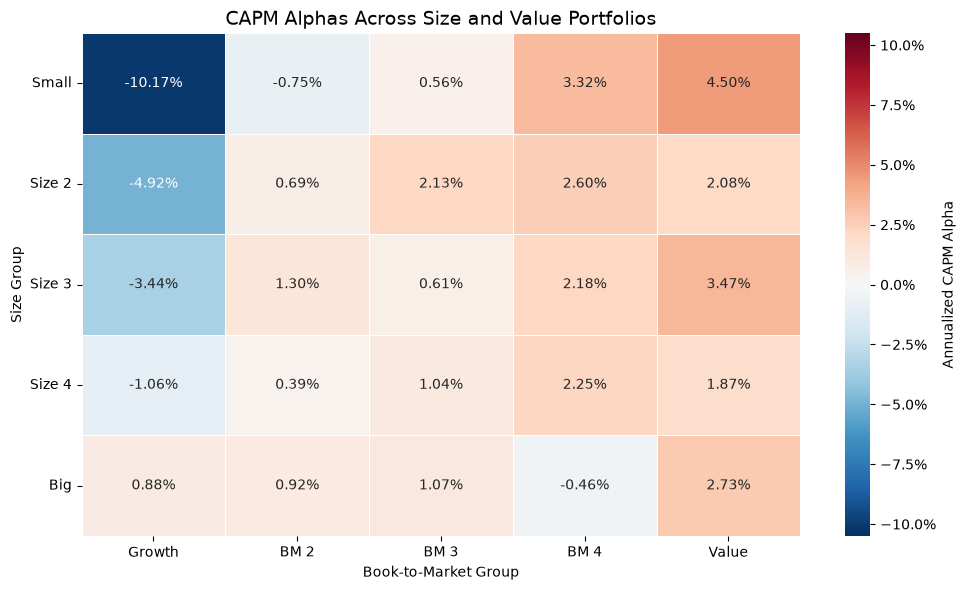

In [98]:
from matplotlib.ticker import PercentFormatter

alpha_matrix = capm_stats["Alpha"].to_numpy().reshape(5, 5)

fig, ax = plt.subplots(figsize = (10, 6))

sns.heatmap(alpha_matrix, annot = True, fmt = ".2%", cmap = "RdBu_r", center = 0, vmin = -0.105, vmax = 0.105,
            xticklabels = ["Growth", "BM 2", "BM 3", "BM 4", "Value"], yticklabels = ["Small", "Size 2", "Size 3", "Size 4", "Big"],
            linewidths = 0.5, cbar_kws = {"label": "Annualized CAPM Alpha", "format": PercentFormatter(1.0)}, ax = ax)

ax.set_title("CAPM Alphas Across Size and Value Portfolios", fontsize = 14)
ax.set_xlabel("Book-to-Market Group")
ax.set_ylabel("Size Group")
ax.tick_params(axis = "y", rotation = 0)

plt.tight_layout()
plt.show()

### 5. Joint Test of Alphas

We measured how well the CAPM performs by checking the MAE of the time-series alphas.

Under classic statistical assumptions, we can test the null hypothesis that the CAPM works by calculating,

$$
H = T\left[1+\left(\text{SR}_{\text{mkt}}\right)^2\right]^{-1} \boldsymbol{\alpha}'\boldsymbol{\Sigma}_\epsilon^{-1}\boldsymbol{\alpha}
$$

This test statistic has a chi-squared distribution...

$$H\sim \chi^2_n$$

Note the following:

- $\boldsymbol{\alpha}$ is an $n\times 1$ vector of the individual regression alphas, $\alpha^i$.
- $\boldsymbol{\Sigma}_\epsilon$ is the $n\times n$ covariance matrix of the time-series of regression residuals, $\epsilon^i$, corresponding to each regression. 
- $\text{SR}_{\text{mkt}}$ is the monthly Sharpe ratio of $\tilde{r}^{\text{mkt}}$.

The test statistic, $H$, has a chi-squared distribution with $n=25$ degrees of freedom. So under the null hypothesis of the CAPM holding, $H$ should be small, and the distribution allows us to calculate the probability of seeing such a large $H$, conditional on the CAPM being true.

- Which is a stricter test: checking whether any of the $n$ values of $\alpha^i$ have a statistically significant t-test or checking whether $H$ calculated above is significant?

    > The joint (H) test provides a more comprehensive test of CAPM because it evaluates whether all 25 portfolio alphas are simultaneously zero while accounting for correlations among their regression residuals. 
    > 
    > In contrast, individual t-tests examine each alpha separately, and checking whether any of the 25 tests is significant introduces a multiple-testing problem. 
    > 
    > The joint test is therefore more rigorous for evaluating CAPM as a whole, although it is not necessarily more difficult to reject in every sample.

- Conceptually, how does the test-statistic $H$ relate to checking whether $\tilde{r}^{\text{mkt}}$ spans the tangency portfolio?

    > The joint (H) test evaluates whether the market portfolio is mean-variance efficient relative to the 25 test portfolios. 
    > 
    > Under CAPM, the market portfolio should span the tangency portfolio, meaning that adding other risky assets cannot improve the maximum attainable Sharpe ratio. If all 25 alphas are zero, these portfolios offer no additional mean-variance investment opportunities beyond the market. Conversely, nonzero alphas may allow investors to construct portfolios with higher risk-adjusted returns.
    > 
    > Thus, a significant (H) statistic suggests that the market portfolio does not span the tangency portfolio.

In [72]:
#align market and portfolio returns, keeping complete observations
joint_data = excess_returns.join(market.rename("Mkt-RF")).dropna()

#re-estimate the regressions on the common sample
X = sm.add_constant(joint_data["Mkt-RF"])
Y = joint_data[excess_returns.columns]

model = sm.OLS(Y, X).fit()

alpha = model.params.loc["const"].to_numpy()
sigma_e = model.resid.cov().to_numpy()

sr_mkt = joint_data["Mkt-RF"].mean() / joint_data["Mkt-RF"].std()

T, n = Y.shape

H = T / (1 + sr_mkt**2) * (alpha @ np.linalg.solve(sigma_e, alpha))

p_value = chi2.sf(H, df = n)

print(f"H statistic: {H:.4f}")
print(f"Degrees of freedom: {n}")
print(f"P-value: {p_value:.6f}")

H statistic: 131.5226
Degrees of freedom: 25
P-value: 0.000000


> The joint alpha test produces an (H) statistic of 131.5226 with 25 degrees of freedom and a p-value below 0.000001. 
> 
> Since the test statistic substantially exceeds the 5% chi-squared critical value of approximately 37.65, we reject the null hypothesis that all 25 CAPM alphas are jointly zero. 
> 
> This provides strong statistical evidence that market beta alone does not adequately explain the portfolios' excess returns. The rejection also suggests that the market portfolio is not mean-variance efficient relative to the investment opportunity set containing these 25 portfolios, consistent with DFA's motivation for considering additional size and value factors.

# 4. Beyond CAPM

### 1.

Re-do the analysis of `3.2` and `3.3`, but instead of using the market return as the factor, use a new factor: the in-sample tangency portfolio of the $n=25$ portfolios. 

Use the portfolio excess returns from Section 3. The new factor is the tangency portfolio formed from these 25 portfolios.

- Calculate $\tilde{r}^{\text{tan}}$ by solving the MV optimization of the $n$ excess returns. 
- Consider this to be your single factor.

Instead of testing the CAPM, you will test the tangency-factor model:

$$
\mathbb{E}\left[\tilde{r}_{t}^{i}\right] = \beta^{i,\text{tan}}\; \mathbb{E}\left[\tilde{r}_{t}^{\text{tan}}\right]
$$

What do you find?

### 2.

Re-do the analysis of `3.2` and `3.3`, but instead of using only the `Mkt-RF` factor, use `Mkt-RF`, `SMB`, and `HML`. 

Use the portfolio excess returns from Section 3. All three factors are already excess returns; do not subtract `RF` from them.

Thus, instead of testing the CAPM, you will be testing the Fama-French 3-Factor Model.

$$
\mathbb{E}\left[\tilde{r}_{t}^{i}\right] = \beta^{i,\text{mkt}}\; \mathbb{E}\left[\tilde{r}_{t}^{\text{mkt}}\right] + \beta^{i,\text{size}}\; \mathbb{E}\left[\tilde{r}_{t}^{\text{size}}\right] + \beta^{i,\text{val}}\; \mathbb{E}\left[\tilde{r}_{t}^{\text{val}}\right]
$$